# AlexNet Neural Network for CIFAR-10


### Options


In [1]:
batch_size = 50
EPOCHS = 1

### Setup our model


In [2]:
from torch import nn
import torch

import brevitas.nn as qnn
from brevitas.core.quant import QuantType
import torch.nn.functional as F

from brevitas.quant import Int8WeightPerTensorFixedPoint, Int8ActPerTensorFixedPoint, Int8BiasPerTensorFloatInternalScaling, Int8BiasPerTensorFixedPointInternalScaling


class QuantAlexNet(nn.Module):
    
    def __init__(self):
        super(QuantAlexNet, self).__init__()
        self.features = nn.Sequential(
            qnn.QuantIdentity(act_quant=Int8ActPerTensorFixedPoint, bit_width=8, return_quant_tensor=True),
            qnn.QuantConv2d(3, 96, 11, 4, weight_quant=Int8WeightPerTensorFixedPoint, bias=False, weight_bit_width=8),
            qnn.QuantReLU(act_quant=Int8ActPerTensorFixedPoint, bit_width=8, return_quant_tensor=True),
            nn.MaxPool2d(3, 2),
            qnn.QuantConv2d(96, 256, 5, 1, 2, weight_quant=Int8WeightPerTensorFixedPoint, bias=False, weight_bit_width=8),
            qnn.QuantReLU(act_quant=Int8ActPerTensorFixedPoint, bit_width=8, return_quant_tensor=True),
            nn.MaxPool2d(3, 2),
            qnn.QuantConv2d(256, 384, 3, 1, 1, weight_quant=Int8WeightPerTensorFixedPoint, bias=False, weight_bit_width=8),
            qnn.QuantReLU(act_quant=Int8ActPerTensorFixedPoint, bit_width=8, return_quant_tensor=True),
            qnn.QuantConv2d(384, 384, 3, 1, 1, weight_quant=Int8WeightPerTensorFixedPoint, bias=False, weight_bit_width=8),
            qnn.QuantReLU(act_quant=Int8ActPerTensorFixedPoint, bit_width=8, return_quant_tensor=True),
            qnn.QuantConv2d(384, 256, 3, 1, 1, weight_quant=Int8WeightPerTensorFixedPoint, bias=False, weight_bit_width=8),
            qnn.QuantReLU(act_quant=Int8ActPerTensorFixedPoint, bit_width=8, return_quant_tensor=True),
            nn.MaxPool2d(3, 2)  
        )

        self.classifier = nn.Sequential(
            nn.Dropout(),
            qnn.QuantLinear(256 * 6 * 6, 4096, output_quant=Int8ActPerTensorFixedPoint, bias=False, weight_quant=Int8WeightPerTensorFixedPoint, weight_bit_width=8),
            qnn.QuantReLU(act_quant=Int8ActPerTensorFixedPoint, bit_width=8, return_quant_tensor=True),
            nn.Dropout(),
            qnn.QuantLinear(4096, 4096, output_quant=Int8ActPerTensorFixedPoint, bias=False, weight_quant=Int8WeightPerTensorFixedPoint, weight_bit_width=8),
            qnn.QuantReLU(act_quant=Int8ActPerTensorFixedPoint, bit_width=8, return_quant_tensor=True),
            qnn.QuantLinear(4096, 1000, output_quant=Int8ActPerTensorFixedPoint, bias=False, weight_quant=Int8WeightPerTensorFixedPoint, weight_bit_width=8),
        )
        
    def forward(self, x):
        out = self.features(x)
        out = torch.flatten(out, 1)
        out = self.classifier(out)
        return out

model = QuantAlexNet()
print(model)

QuantAlexNet(
  (features): Sequential(
    (0): QuantIdentity(
      (input_quant): ActQuantProxyFromInjector(
        (_zero_hw_sentinel): StatelessBuffer()
      )
      (act_quant): ActQuantProxyFromInjector(
        (_zero_hw_sentinel): StatelessBuffer()
        (fused_activation_quant_proxy): FusedActivationQuantProxy(
          (activation_impl): Identity()
          (tensor_quant): RescalingIntQuant(
            (int_quant): IntQuant(
              (float_to_int_impl): RoundSte()
              (tensor_clamp_impl): TensorClamp()
              (delay_wrapper): DelayWrapper(
                (delay_impl): _NoDelay()
              )
              (input_view_impl): Identity()
            )
            (scaling_impl): ParameterFromRuntimeStatsScaling(
              (stats_input_view_shape_impl): OverTensorView()
              (stats): _Stats(
                (stats_impl): AbsPercentile()
              )
              (restrict_scaling_impl): PowerOfTwoRestrictValue(
                (

In [3]:

import torch
torch.cuda.empty_cache()

use_gpu = torch.cuda.is_available()
#use_gpu = False # Dataset so small that CPU is faster
if use_gpu:
    model = model.cuda()
    print("USE GPU")
else:
    print("USE CPU")

USE GPU


### Setting up the data


In [4]:
import torch
import torchvision
import torchvision.transforms as transforms
from torchvision.datasets import CIFAR10
from torch.utils.data import DataLoader

transform = transforms.Compose([
    transforms.Resize((227, 227)),  # Resize images to 227x227
    transforms.ToTensor(),  # Convert images to PyTorch tensors
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),  # Normalize
])

# Load the CIFAR-10 dataset
training_set = CIFAR10(root='./data', train=True, transform=transform, download=True)
validation_set = CIFAR10(root='./data', train=False, transform=transform, download=True)

# Create data loaders
training_loader = DataLoader(training_set, batch_size=batch_size, shuffle=True)
validation_loader = DataLoader(validation_set, batch_size=batch_size, shuffle=False)

# Report split sizes
print('Training set has {} instances'.format(len(training_set)))
print('Validation set has {} instances'.format(len(validation_set)))


Files already downloaded and verified
Files already downloaded and verified
Training set has 50000 instances
Validation set has 10000 instances


## Exporting of Data

In [5]:
import numpy as np

x_val = []
y_val = []

x_train = []
y_train = []

for (i, (x, y)) in enumerate(validation_set):
    if i >= 1000:
        break
    x_val.append(x.detach().numpy())
    tmp = np.full(shape=(1000, ), fill_value=0)
    tmp[y] = 1
    y_val.append(tmp)


np.save("./export/cifar-10/x_test.npy", np.array(x_val, dtype=np.float32))
np.save("./export/cifar-10/y_test.npy", np.array(y_val, dtype=np.float32))

del x_val
del y_val

for (i, (x, y)) in enumerate(training_set):
    if i >= 1000:
        break
    x_train.append(x.detach().numpy())
    tmp = np.full(shape=(1000, ), fill_value=0)
    tmp[y] = 1
    y_train.append(tmp)

np.save("./export/cifar-10/x_train.npy", np.array(x_train, dtype=np.float32))
np.save("./export/cifar-10/y_train.npy", np.array(y_train, dtype=np.float32))

## Visualization of Data

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.076419204..1.028].


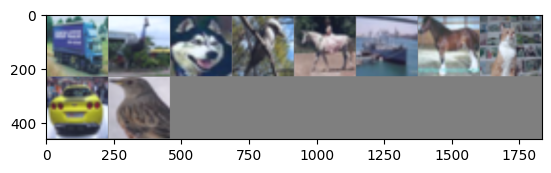

In [6]:
import matplotlib.pyplot as plt
import numpy as np

# Helper function for inline image display
def matplotlib_imshow(img, one_channel=False):
    if one_channel:
        img = img.mean(dim=0)
    img = img / 5 + 0.5     # unnormalize
    npimg = img.numpy()
    
    if one_channel:
        plt.imshow(npimg,)
    else:
        plt.imshow(np.transpose(npimg, (1, 2, 0)))

dataiter = iter(training_loader)
images, labels = next(dataiter)

# Create a grid from the images and show them
img_grid = torchvision.utils.make_grid(images[0:10:])
matplotlib_imshow(img_grid, one_channel=False)

## Training

In [7]:
from torch.autograd import Variable
import datetime as d
from torch.utils.tensorboard import SummaryWriter

torch.cuda.empty_cache()

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.001)

def train_one_epoch(epoch_index, tb_writer):
    running_loss = 0.
    last_loss = 0.

    # Here, we use enumerate(training_loader) instead of
    # iter(training_loader) so that we can track the batch
    # index and do some intra-epoch reporting
    for i, data in enumerate(training_loader):
        # Every data instance is an input + label pair
        inputs, labels = data
        inputs = inputs.to("cuda:0" if use_gpu else "cpu")
        labels = labels.to("cuda:0" if use_gpu else "cpu")

        # Zero your gradients for every batch!
        optimizer.zero_grad()

        # Make predictions for this batch
        outputs = model(inputs)

        # Compute the loss and its gradients
        loss = loss_fn(outputs, labels)
        loss.backward()

        # Adjust learning weights
        optimizer.step()

        # Gather data and report
        running_loss += loss.item()
        if i % 100 == 99:
            last_loss = running_loss / 100 # loss per batch
            print('  batch {} loss: {}'.format(i + 1, last_loss))
            tb_x = epoch_index * len(training_loader) + i + 1
            tb_writer.add_scalar('Loss/train', last_loss, tb_x)
            running_loss = 0.
        
        del inputs
        del labels

    return last_loss

# Initializing in a separate cell so we can easily add more epochs to the same run
timestamp = d.datetime.now().strftime('%Y%m%d_%H%M%S')
writer = SummaryWriter('runs/mnist_trainer_{}'.format(timestamp))
epoch_number = 0

best_vloss = 1_000_000.

for epoch in range(EPOCHS):
    print('EPOCH {}:'.format(epoch_number + 1))

    # Make sure gradient tracking is on, and do a pass over the data
    model.train(True)
    avg_loss = train_one_epoch(epoch_number, writer)


    running_vloss = 0.0
    # Set the model to evaluation mode, disabling dropout and using population
    # statistics for batch normalization.
    model.eval()

    # Disable gradient computation and reduce memory consumption.
    with torch.no_grad():
        for i, vdata in enumerate(validation_loader):
            vinputs, vlabels = vdata
            voutputs = model(vinputs.to("cuda:0" if use_gpu else "cpu"))
            vloss = loss_fn(voutputs.to("cuda:0" if use_gpu else "cpu"), vlabels.to("cuda:0" if use_gpu else "cpu"))
            running_vloss += vloss

            del voutputs
            del vlabels

    avg_vloss = running_vloss / (i + 1)
    print('LOSS train {} valid {}'.format(avg_loss, avg_vloss))

    # Log the running loss averaged per batch
    # for both training and validation
    writer.add_scalars('Training vs. Validation Loss',
                    { 'Training' : avg_loss, 'Validation' : avg_vloss },
                    epoch_number + 1)
    writer.flush()

    # Track best performance, and save the model's state
    if avg_vloss < best_vloss:
        best_vloss = avg_vloss

    epoch_number += 1

EPOCH 1:


/home/maxim/Documents/Uni/BA/bachelor-thesis/.venv/lib/python3.10/site-packages/torch/_tensor.py:1362: UserWarning: Named tensors and all their associated APIs are an experimental feature and subject to change. Please do not use them for anything important until they are released as stable. (Triggered internally at ../c10/core/TensorImpl.h:1900.)
  return super().rename(names)
/home/maxim/Documents/Uni/BA/bachelor-thesis/.venv/lib/python3.10/site-packages/torch/nn/modules/conv.py:456: UserWarning: Defining your `__torch_function__` as a plain method is deprecated and will be an error in future, please define it as a classmethod. (Triggered internally at ../torch/csrc/utils/python_arg_parser.cpp:368.)
  return F.conv2d(input, weight, bias, self.stride,
/tmp/ipykernel_99605/557265353.py:44: UserWarning: Defining your `__torch_function__` as a plain method is deprecated and will be an error in future, please define it as a classmethod. (Triggered internally at ../torch/csrc/utils/python_a

  batch 100 loss: 6.905645089149475
  batch 200 loss: 6.903075628280639
  batch 300 loss: 6.899500308036804
  batch 400 loss: 6.893577389717102
  batch 500 loss: 6.882645425796508
  batch 600 loss: 6.862783999443054
  batch 700 loss: 6.85076488494873
  batch 800 loss: 6.846969113349915
  batch 900 loss: 6.845675377845764
  batch 1000 loss: 6.8448674631118775
LOSS train 6.8448674631118775 valid 6.844761848449707


## Inference test

In [14]:
import time

latency = 0.0

total_correct = 0
total_samples = 0

#del training_loader
torch.cuda.empty_cache()
import gc
gc.collect()
print(torch.cuda.memory_allocated(device='cuda:0'))
print(torch.cuda.memory_reserved(device='cuda:0'))
for images, labels in validation_loader:
    # Move the data to the device (CPU or GPU)
    start = time.perf_counter_ns()
    # Forward pass
    outputs = model(images.to("cuda:0" if use_gpu else "cpu"))
    end = time.perf_counter_ns()
    
    latency = float(end - start) / 1000
    _, predicted = torch.max(outputs, 1)

    # Update the running total of correct predictions and samples
    total_correct += (predicted.to("cuda:0" if use_gpu else "cpu") == labels.to("cuda:0" if use_gpu else "cpu")).sum().item()
    total_samples += labels.size(0)

    del outputs
    del predicted
    del labels

print("total latency", latency)

# Calculate the accuracy for this epoch
accuracy = 100 * total_correct / total_samples
print(f'Accuracy = {accuracy:.2f}%')
print("Total misses: " + str(total_samples - total_correct) + " of " + str(total_samples))

2906269184
2963275776


## Export model

In [18]:
import brevitas.onnx as bo


exported_model = bo.export_qonnx(model, args=torch.randn(1, 3, 227, 227).to('cuda:0' if use_gpu else 'cpu'), export_path="Alexnet_qonnx.onnx", opset_version=13)